# Tasks



# Preamble

## Download and unzip dataset

In [1]:
# uncomment only if fresh download is desired

#!wget 'https://www.kaggle.com/api/v1/datasets/download/asaniczka/uk-optimal-product-price-prediction'
#!unzip uk-optimal-product-price-prediction

## Loading libraries

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Visualisation settings

In [3]:
# Configuration to set so that all the Seaborn figures come out with this size
%config Inlinebackend.figure_format= 'retina'
# Set the Seaborn context to "poster" for larger text and figures
sns.set_context("poster")

# Set the default figure size for Seaborn plots
sns.set_theme(rc={"figure.figsize": (12., 6.)})

# Set the Seaborn style to "whitegrid" for a white background with gridlines
sns.set_style("whitegrid")

In [4]:
# formatting number display
pd.set_option('display.float_format', '{:.2f}'.format)


## Loading dataset

In [5]:

# use `uid` as index
df = pd.read_csv('amz_uk_price_prediction_dataset.csv',index_col='uid')

# EDA and data cleaning

In [6]:
# General overview
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2443651 entries, 1 to 2828593
Data columns (total 8 columns):
 #   Column             Dtype  
---  ------             -----  
 0   asin               object 
 1   title              object 
 2   stars              float64
 3   reviews            int64  
 4   price              float64
 5   isBestSeller       bool   
 6   boughtInLastMonth  int64  
 7   category           object 
dtypes: bool(1), float64(2), int64(2), object(3)
memory usage: 151.5+ MB


In [7]:
# glance at beginning of dataset
df.head()

,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
uid,,,,,,,,
1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.70,98099,23.99,True,0,Hi-Fi Speakers
3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.70,7205,31.99,False,0,Hi-Fi Speakers
5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.60,1881,17.99,False,0,Hi-Fi Speakers


In [8]:
print(df.columns)

Index(['asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


No starting or trailing spaces in column titles. Mixed capitalisation may bother some people, I don't mind here.

In [9]:
# overview of unique values
df.nunique()

asin                 2222742
title                2077591
stars                     42
reviews                19446
price                  82916
isBestSeller               2
boughtInLastMonth         25
category                 296
dtype: int64

In [10]:
# check values for `boughtInLastMonth`, which has suspiciously small number of unique values for a numerical variable
df.boughtInLastMonth.unique()

array([    0,   600,  1000,   200,   100,    50,  2000,   800,   900,
         700,   500,   400,   300,  4000,  3000,  5000,  9000,  7000,
        6000, 50000, 20000, 10000,  8000, 30000, 40000])

**Overview of columns**

categorical:

- `asin`: Amazon Standard Identification Number, unique identifier, could act as alternative to uid
- `title`: listing title/description of product
- `isBestSeller`: bool marking whether the product is classified as bestseller (number one seller within category or subcategory)
- `category`: the product category the item is associated with


numerical:

- `stars`: average evaluation assigned by reviewers
- `reviews`: number of reviews 
- `price`: list price for item
- `boughtInLastMonth`: presumably number of sales in last month on record; limited number of distinct values (25) hence rather categorical in nature (presumably only available in aggregated format for dataset publication)

In [11]:
# check for na values
df.isna().sum()

asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

The dataset contains no NA values, good.

## Exploration of columns

In [12]:

df.describe()

,stars,reviews,price,boughtInLastMonth
count,2443651.00,2443651.00,2443651.00,2443651.00
mean,2.15,480.63,89.24,25.90
std,2.19,5944.12,345.61,240.48
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,9.99,0.00
50%,0.00,0.00,19.09,0.00
75%,4.40,59.00,45.99,0.00
max,5.00,1356658.00,100000.00,50000.00


**Observations**

- `stars`: 
  - range from 0 to 5, 0 presumably corresponding to absence of reviews
  - mean at 2.15 with relatively large dispersion of std=2.19 (considering the 5 point scale)
  - median is at 0, indicating absence of reviews for at least half of the items
- `reviews`:
  - very large range from 0 to over 1.3 mio. reviews
  - supporting insight regarding `stars`, the median of 0 indicates a lack of reviews for at least half of the items
  - relatively low mean of 480 and large std=5944 reflects wide spread of data
- `price`:
  - range from 0 to 100 000 GBP
  - possible follow up on items with 0GBP price!
  - median at 19.09GBP, mean at 89.24GBP, indicating that majority of items are in lower price range
- `boughtInLastMonth`:
  - range from 0 to 50 000
  - as found above, provided quasi-categorically (with 25 distinct numerical values)
  - value 0 up to 75-percentile


In [13]:
# generating lists of column titles for for numerical and categorical data
num = df.select_dtypes(include="number").columns
cat = df.select_dtypes(exclude="number").columns


In [14]:
nullprice = df.loc[df.price == 0]
print(len(nullprice))
nullprice

20


,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
uid,,,,,,,,
367018,B07TYXW54L,Exercises with Resistance Loop Bands: 40+ Exer...,4.10,94,0.00,False,0,Sports & Outdoors
589599,B003WL4O38,Operation Mincemeat: The True Spy Story that C...,4.50,5795,0.00,False,0,PC & Video Games
590132,B005KKRRVK,Kensuke’s Kingdom,4.70,4565,0.00,False,0,PC & Video Games
590332,B09WRXGQZL,"Faith, Hope and Carnage",4.70,546,0.00,False,0,PC & Video Games
855945,B07T7L39TN,Never Split the Difference: Negotiating as if ...,4.60,39112,0.00,True,0,School & Educational Supplies
905582,B00E3SYBWS,"Go for the Gold, Atalanta! (Myth-O-Mania Book 8)",4.70,190,0.00,False,0,Games & Game Accessories
905932,B0BJQQZ79H,Battle of the Fang: Space Marine Battles: Warh...,4.60,166,0.00,False,0,Games & Game Accessories
908772,B07YGP8442,100 Years of Leeds United,4.80,1349,0.00,False,0,Games & Game Accessories
911439,B0BLFPRMZH,"Dungeons & Guardians: Battleborne, Book III",4.70,2421,0.00,False,0,Games & Game Accessories


There are twenty datapoints with a price of 0GBP. They have non-zero values for stars and reviews, so they might be out-of-sale at the moment. Removing them might remove unnecessary bias from the price data, although this is a comparatively small number of datapoints to have a major impact.

In [15]:
# remove 20 items with zero price
df_clean = df.loc[df.price != 0]
len(df_clean)

2443631

In [16]:
df_clean.price.describe()

count   2443631.00
mean         89.24
std         345.61
min           0.01
25%           9.99
50%          19.09
75%          45.99
max      100000.00
Name: price, dtype: float64

The minimum price is now 1p, otherwise no major impact on descriptive stats.

In [17]:
df.category.unique()

array(['Hi-Fi Speakers', 'CD, Disc & Tape Players', 'Wearable Technology',
       'Light Bulbs', 'Bathroom Lighting',
       'Heating, Cooling & Air Quality', 'Coffee & Espresso Machines',
       'Lab & Scientific Products', 'Smart Speakers',
       'Motorbike Clothing', 'Motorbike Accessories',
       'Motorbike Batteries', 'Motorbike Boots & Luggage',
       'Motorbike Chassis', 'Handmade Home & Kitchen Products',
       'Hardware', 'Storage & Home Organisation',
       'Fireplaces, Stoves & Accessories', 'PC Gaming Accessories',
       'USB Gadgets', 'Blank Media Cases & Wallets', 'Car & Motorbike',
       'Boys', 'Sports & Outdoors', 'Microphones', 'String Instruments',
       'Karaoke Equipment', 'PA & Stage',
       'General Music-Making Accessories', 'Wind Instruments',
       'Handmade Gifts', 'Fragrances', 'Calendars & Personal Organisers',
       'Furniture & Lighting', 'Computer Printers', 'Ski Goggles',
       'Snowboards', 'Skiing Poles', 'Downhill Ski Boots',
       'Hiki

In [18]:
df.loc[df.isBestSeller == True,['title','category','boughtInLastMonth']].head(10)

,title,category,boughtInLastMonth
uid,,,
2,"Anker Soundcore mini, Super-Portable Bluetooth...",Hi-Fi Speakers,0
16,"Echo Dot Kids (5th generation, 2022 release) |...",Hi-Fi Speakers,0
18,"Echo Dot Kids (5th generation, 2022 release) |...",Hi-Fi Speakers,0
37,Bose Solo Soundbar Series II - TV Speaker with...,Hi-Fi Speakers,0
56,"Sanyun SW208 3"" Active Bluetooth 5.0 Bookshelf...",Hi-Fi Speakers,0
82,Bose Home Speaker 500 with Alexa Built In - Tr...,Hi-Fi Speakers,0
131,Sumvision PYSC Wireless Bluetooth LED Tower Sp...,Hi-Fi Speakers,0
167,Logitech Z407 Bluetooth Computer Speakers with...,Hi-Fi Speakers,0
213,"Echo Dot (5th generation, 2022 release) Kids |...",Hi-Fi Speakers,0


There are 7980 bestsellers and there can be more than one bestseller per category.

Histogram 

<Axes: xlabel='stars', ylabel='Count'>

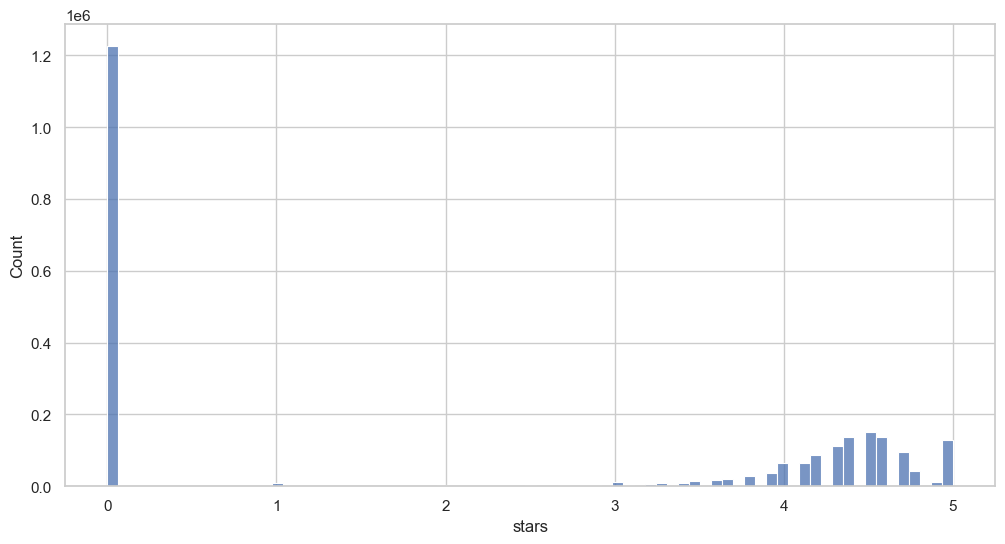

In [19]:
sns.histplot(df,x='stars')


# Part I: Business questions

## Categories

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [20]:
pd.set_option('display.max_columns', None)  # or 1000
pd.set_option('display.max_rows', None)  # or 1000
pd.set_option('display.max_colwidth', None)  # or 199

cat_freq = df_clean.category.value_counts().reset_index()

display(cat_freq.head(5))

,category,count
0,Sports & Outdoors,836260
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


The five most listed product categories are: `Sports & Outdoors` (by far), followed by `Beauty`, `Handmade Clothing, Shoes & Accessories`, `Bath & Body` and `Birthday Gifts`.

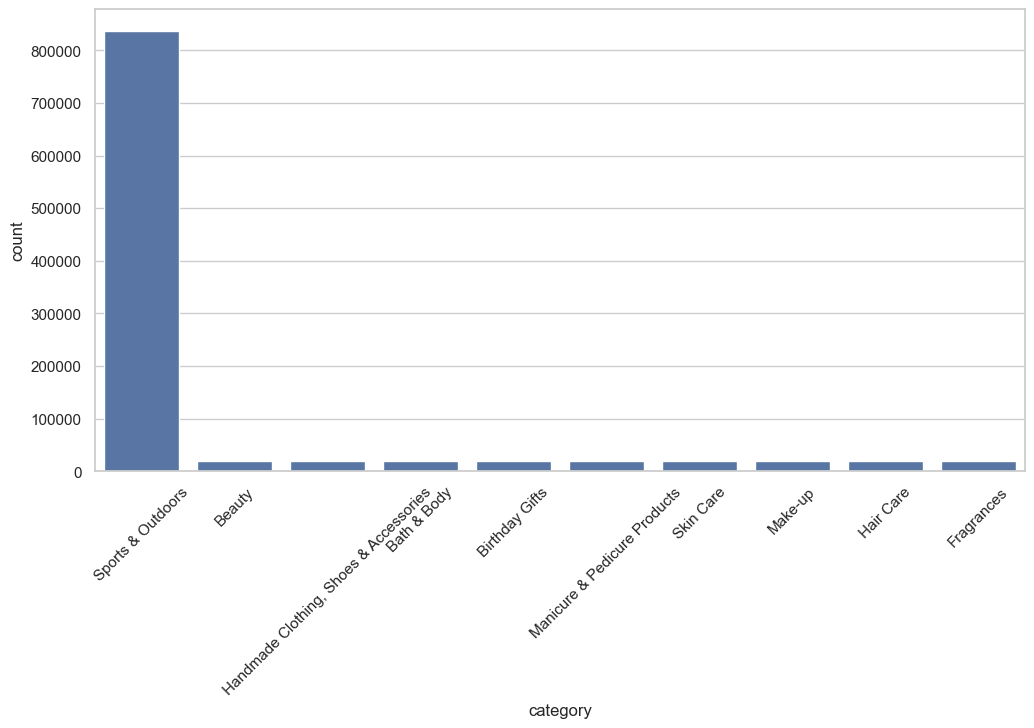

In [21]:
sns.barplot(cat_freq[:10],x='category',y='count')
plt.xticks(rotation=45);

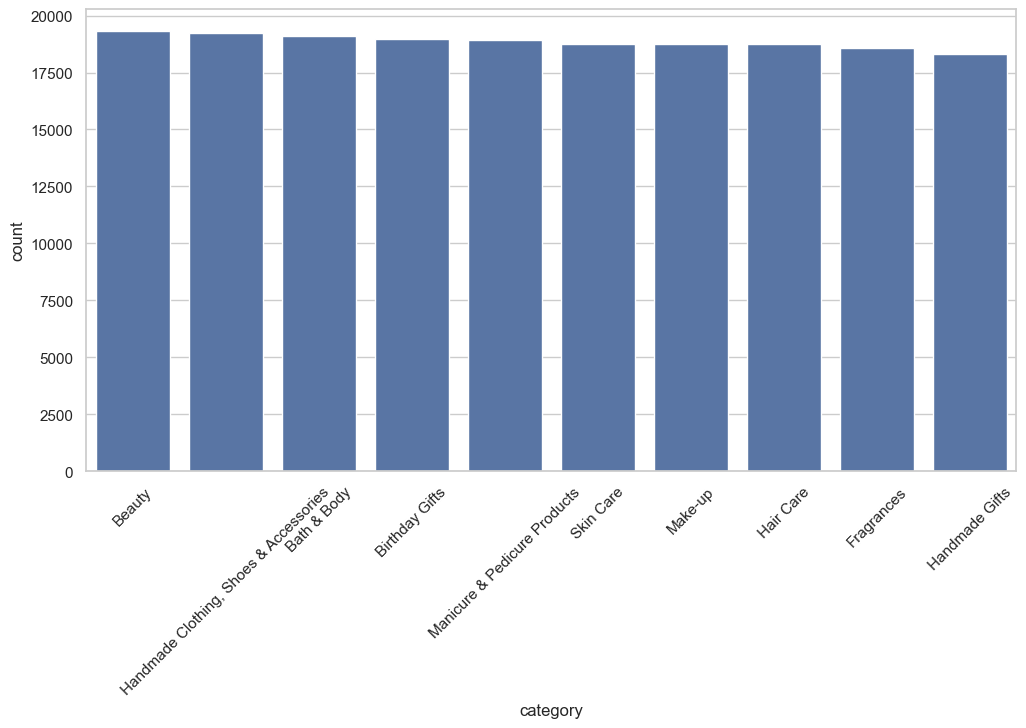

In [22]:
sns.barplot(cat_freq[1:11],x='category',y='count')
plt.xticks(rotation=45);

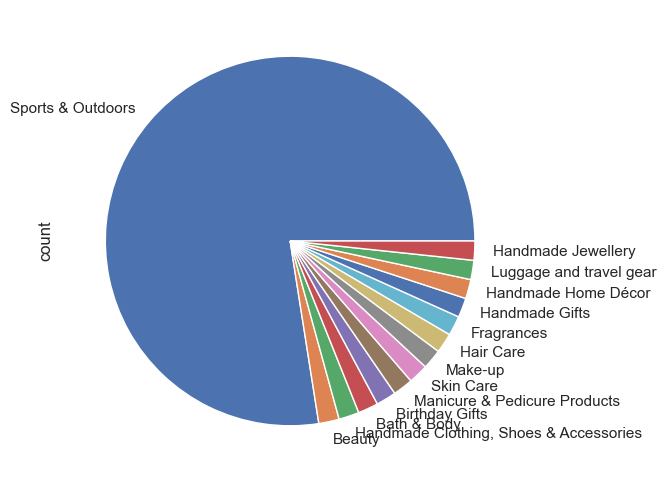

In [23]:
df_clean.category.value_counts()[:14].plot.pie(y='category');

`Sports & Outdoors` massively dominates the other categories (as already suggested by the numerical data.)

# Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [24]:
# measures of centrality
print('mean price: ', round(df_clean.price.mean(),2))
print('median price: ', df_clean.price.median())
print('mode price: ', df_clean.price.mode()[0])

# for reference
print('\nmaximum value for price: ',df_clean.price.max())


mean price:  89.24
median price:  19.09
mode price:  9.99

maximum value for price:  100000.0


The average price point of 89.24GBP is much higher than the median and the mode of the pricelist. This suggests that the mean value is driven up by items with a price point going much higher than the mode or median values (cf. also the maximum of 100 000GBP observed above). Correspondingly, one would expect a rather high level of dispersion.

In [25]:
# measures of dispersion
print('price variance: ', df_clean.price.var())
print('price standard deviation: ', df_clean.price.std())
print('range for price: ',df_clean.price.max()-df_clean.price.min())

q25=df_clean.price.quantile(.25)
q75=df_clean.price.quantile(.75)

print('25-percentile: ', q25)
print('75-percentile: ', q75)
print('interquartile range: ', q75-q25)


price variance:  119446.39774351795
price standard deviation:  345.6101817706156
range for price:  99999.99
25-percentile:  9.99
75-percentile:  45.99
interquartile range:  36.0


As expected, there is a high variance and standard deviation. We know that price values do not/cannot go under 0, so a standard deviation far exceeding the difference between mean and the minimum value suggests that the points driving up the standard deviation must come from the other, higher side of the mean, again indicating a skewed distribution with a large number of values below the mean and a smaller number of price points much higher than the mean.
We have noted the high range above already. The interquartile range is fairly small at 36, suggesting that a large portion of the data are not spread that far, again supporting the insight that a small number of very high values are driving up the standard deviation.

# Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [26]:
# measures of centrality
print('mean rating: ', round(df_clean.stars.mean(),2))
print('median rating: ', df_clean.stars.median())
print('mode rating: ', df_clean.stars.mode()[0])

mean rating:  2.15
median rating:  0.0
mode rating:  0.0


There seems to be a large number of 0 ratings, since both the median and the mode are 0. These are probably products without any reviews. The mean is below half of the maximum, but likely skewed by this prevalence of 0 values.

This is confirmed by the much higher mean of the subset of data with non-zero star ratings, which is at over 4.3.

In [27]:
# mean of non-zero star ratings
df_clean.loc[df_clean.stars > 0,'stars'].mean()

np.float64(4.319157135937076)

In [28]:
# measures of dispersion
print('stars variance: ', df_clean.stars.var())
print('stars standard deviation: ', df_clean.stars.std())
print('range for stars: ',df_clean.stars.max()-df_clean.stars.min())

q25=df_clean.stars.quantile(.25)
q75=df_clean.stars.quantile(.75)

print('25-percentile: ', q25)
print('75-percentile: ', q75)
print('interquartile range: ', q75-q25)


stars variance:  4.817425709696724
stars standard deviation:  2.194863483157147
range for stars:  5.0
25-percentile:  0.0
75-percentile:  4.4
interquartile range:  4.4


The ratings have a rather large dispersion with a standard deviation of 2.19 and an interquartile range of 4.4 within the total range of 0-5. 

In [29]:
print('skew for stars: ', df_clean.stars.skew())
print('kurtosis for stars: ', df_clean.stars.kurtosis())

skew for stars:  0.08122374937075064
kurtosis for stars:  -1.9260034791941225


The skew of slightly >0 indicates only a very slight right-skew, but generally a roughly symmetric distribution. This value is surprisingly low considering the earlier observation that both mode and median are at 0, suggesting a strong prevalence of those values on the left of the scale.

The skew value is likely distorted by the almost bivalent distribution of data on both ends of the scale, i.e. lots of 0 values and otherwise probably many datapoints towards the high end of the scale. This can be checked in the histogram below.

The low curtosis indicates a relatively flat distribution compared to a normal disribution with thinner tails. Apparently kurtosis does not consider the 0 values, so it ignores the inflation of 0 values in the data and describes the non-zero values. As the non-zero-mean calculated above suggests, those are concentrated towards the higher end of the scale and the curtosis suggests that they are relatively evenly spread.

<Axes: xlabel='stars', ylabel='Count'>

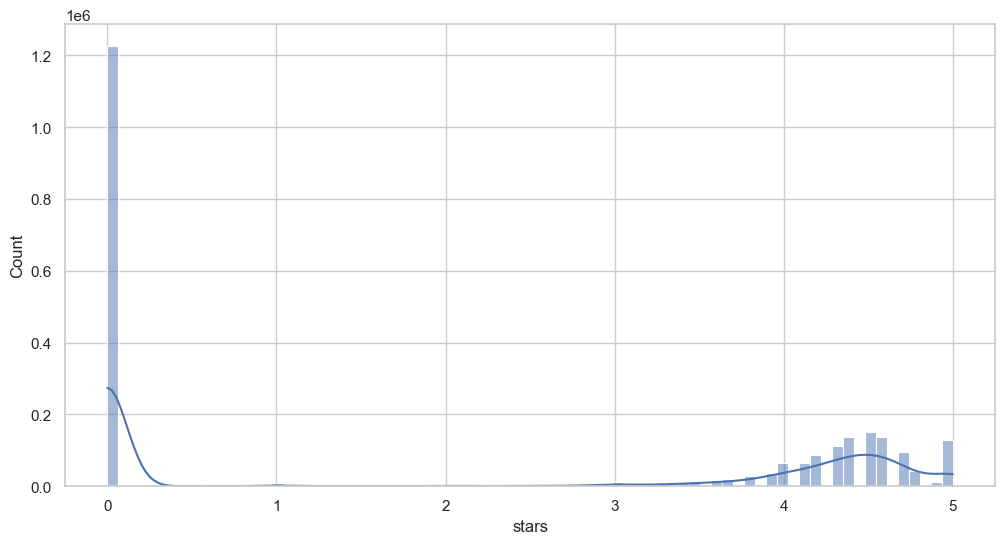

In [33]:
sns.histplot(df_clean,x='stars',kde=True)


The histogram (as well as the closer look at the KDE plot below) show the high number of zero values and the distribution of most remaining values towards the high end of the scale.

<Axes: xlabel='stars', ylabel='Density'>

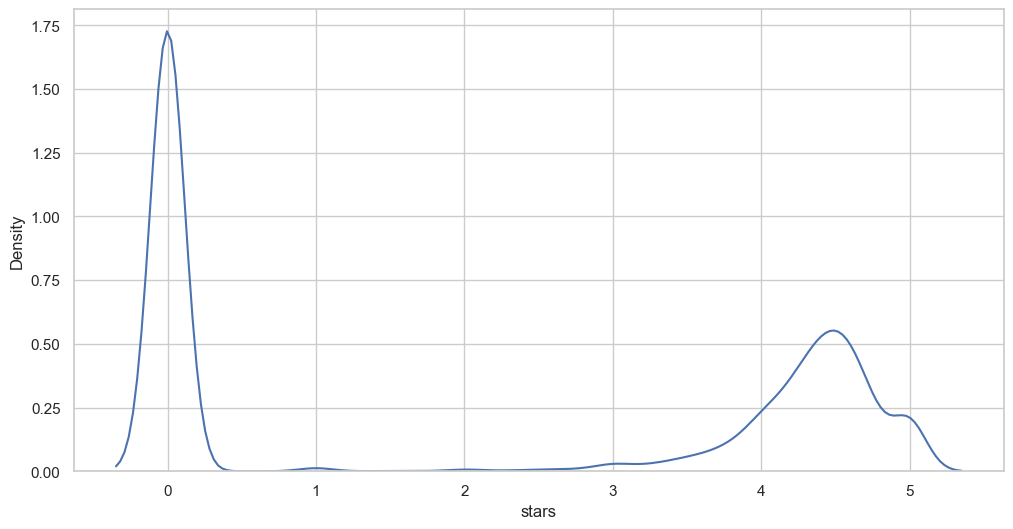

In [34]:
sns.kdeplot(df_clean,x='stars')